# Inverted Pendulum Tutorial

In [1]:
import numpy as np
import pandas as pd
from veery.fuzzing import DisturbanceDistribution
from veery.accessories import check_spec
from veery.viz import plot_rollouts, plot_tree, plot_tree_structure
from veery.mcts import run_MCTS
import disturbances
from environment import InvertedPendulum, PendulumController
from functools import partial

Start by defining the disturbance distribution to pull noisy values from.

In [2]:
D = DisturbanceDistribution(
    Do = disturbances.Do(sigma_theta=0.1, sigma_omega=0.1),
    Da = disturbances.Da(sigma_torque=0),
    Ds = disturbances.Ds(sigma_theta=0, sigma_omega=0)
)

Now, we can sample from our disturbance distribution, as shown below:

In [3]:
x = D.sample()
print(f"Observation disturbance: {x.xo}")

Observation disturbance: {'theta': np.float64(0.10954111183358904), 'omega': np.float64(0.07202366245559697)}


We know we made these Gaussian, but we can check!

/Users/clover/grad/projects/2026/2026-panczyk-rlval/src/veery/fuzzing.py:88: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


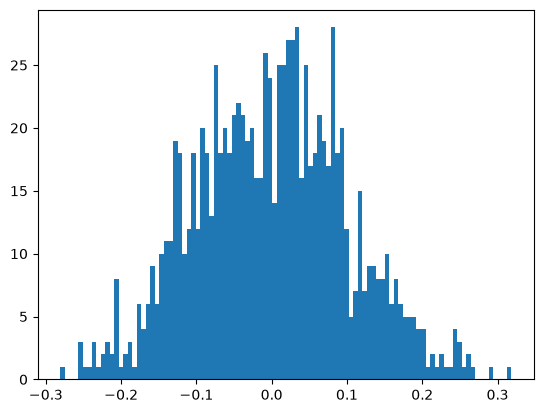

In [4]:
D.plot_samples(dist_type=D.Do, variable="theta")

Great, now we have our disturbances ready to go, let's go find some failures.

# The naive approach

The naive way to do this is to just run a bunch of rollouts and see which ones fail. We count a failed rollout as one containing any single instance (theta value) that crosses the failure threshold, which we define as 45 degrees from perpendicular.  

We start by setting up an inverted pendulum environment:

In [5]:
pendulum = InvertedPendulum(
    m = 1,
    l = 1,
    dt = 0.05,
    episode_length = 1000,
    save_dir = "results/demo"
)

In [6]:
histories, results = pendulum.run_rollouts(
                model = PendulumController(),
                disturbance_distribution=D,
                m = 300,
                psi = partial(check_spec, percent=False)
            )

100%|██████████| 300/300 [00:09<00:00, 32.12it/s]


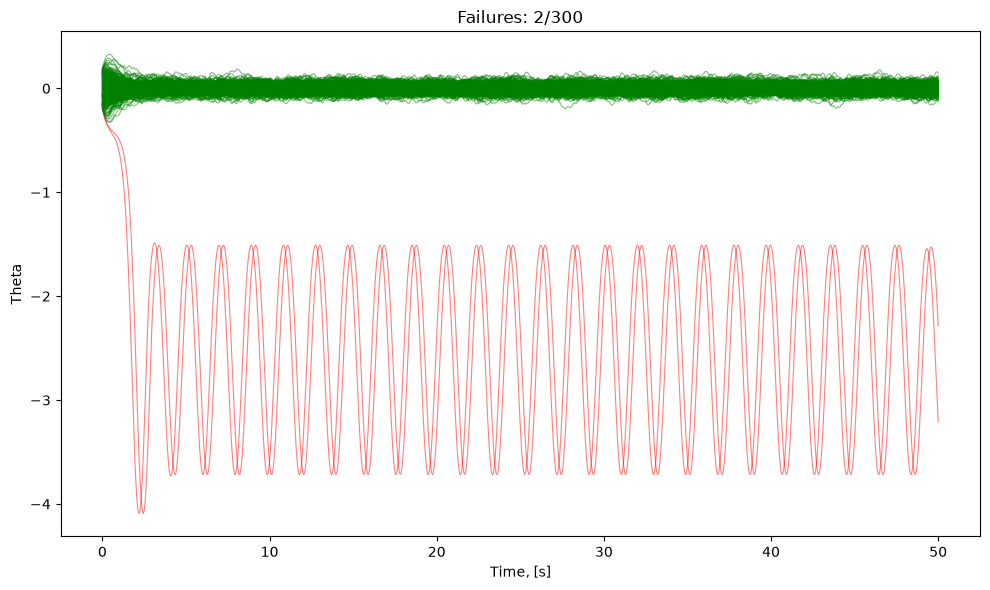

In [7]:
plot_rollouts(histories, results, save_dir="results/figs", ylabel="Theta");

Now, we found one failure in 300 trials. What if we could do that a little faster?

# Finding failures with Monte Carlo Tree Search

In [10]:
thresh = np.pi/4
tree = run_MCTS(
        environment=pendulum, 
        model=PendulumController(),
        disturbance_dist=D, 
        results_path="results/notebook",
        threshold=thresh,
        iterations=100, 
        hyperparams=None,
        percent=False
        )

100%|██████████| 100/100 [00:08<00:00, 11.12it/s]

Saved 0 failures to results/notebook


(<Figure size 1000x1600 with 2 Axes>, <Axes: xlabel='Time, [s]'>)

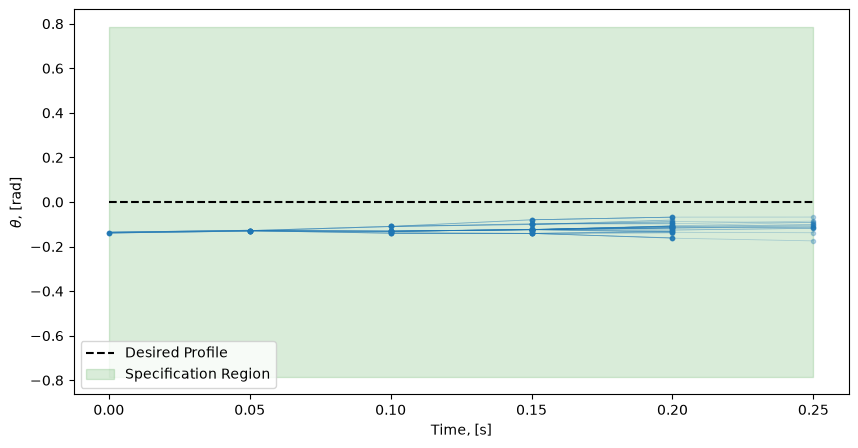

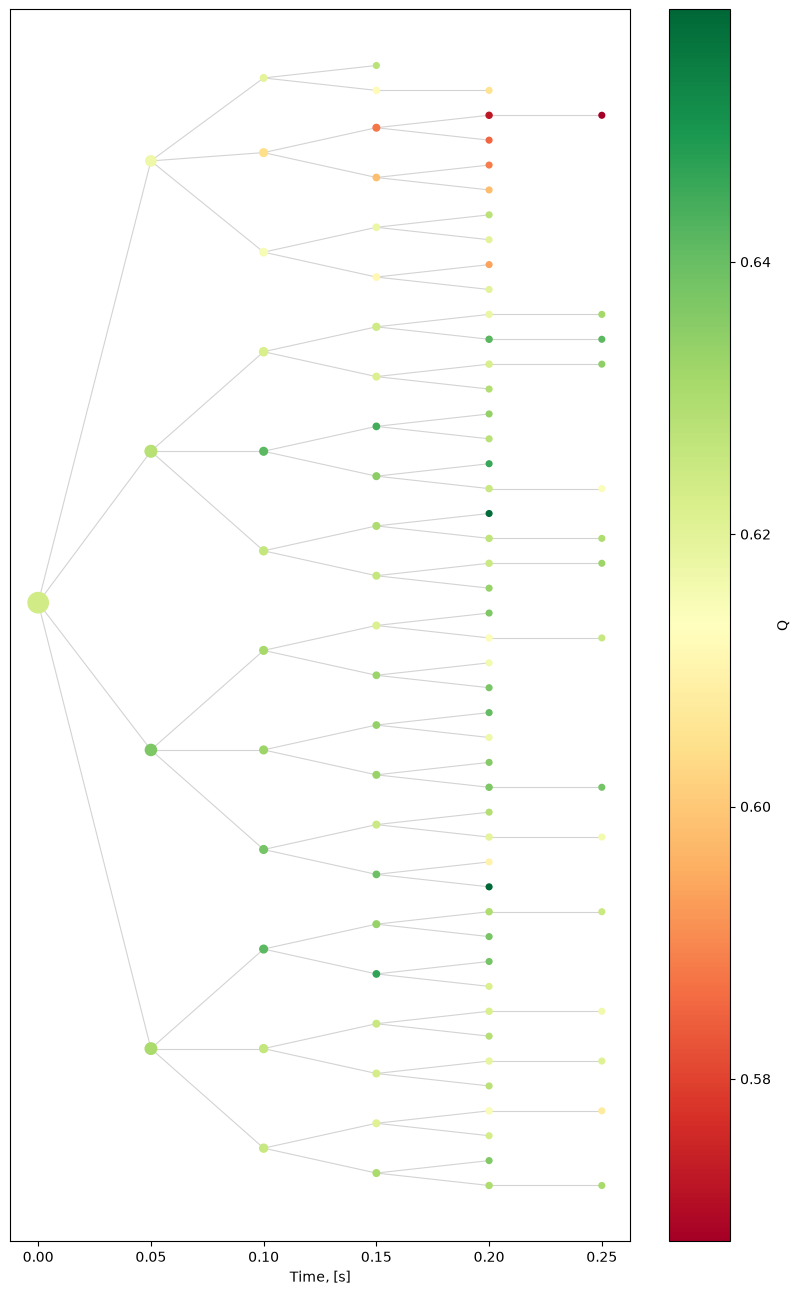

In [11]:
plot_tree(
        tree,
        spec_var=lambda s: s["state"]["theta"],
        profile=pendulum.profile,
        threshold=thresh,
        percent=False,
        ylabel=r"$\theta$, [rad]",
        save_path="results/notebook/tree.png",
    )
plot_tree_structure(
        tree, save_path=f"results/notebook/tree_structure.png"
    )